# D1_07 SPC 관리도와 모니터링 앱

> **오늘 질문:** 10대 설비 중 어디에 이상이 생겼을까?

이 데이터의 설비 한 대에는 **서서히 커지는 진동(드리프트)** 이 숨어 있습니다.
먼저 노트북에서 I 관리도를 그려 찾아보고, 같은 계산을 Streamlit 앱으로 옮깁니다.

| 표시 | 의미 |
|---|---|
| 📋 제공 | 코드가 들어 있습니다. 실행만 하세요 |
| ✍️ 입력 | 설명을 보고 직접 입력하세요 |
| 💬 해석 | 결과를 보고 답을 적어 보세요 |

## 0. 준비 📋

In [1]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib

df = pd.read_parquet("../../data/factory_table.parquet")

## 1. 설비 하나의 일별 진동 ✍️

설비 하나를 골라, 진동(`vibration`)을 하루 평균으로 묶습니다.

> 변수 이름: `equip`, `data`, `daily`

In [2]:
# 힌트: df.resample("D", on="timestamp")["컬럼"].mean()
equip = "MC-01"
data = df[ df['equip_id'] == equip ] # df[ 조건 ], 조건은 equip_id가 "MC-01"인 것만 뽑힘.
daily = data.resample("D", on="timestamp")["vibration"].mean()
daily

timestamp
2025-01-01    2.107143
2025-01-02    2.091429
2025-01-03    2.063636
2025-01-04    2.168889
2025-01-05    1.973636
                ...   
2025-04-06    2.006154
2025-04-07    2.012000
2025-04-08    2.018182
2025-04-09    1.833333
2025-04-10    1.992308
Freq: D, Name: vibration, Length: 100, dtype: float64

## 2. 관리한계 계산 ✍️

관리한계는 **안정된 기간(앞 60일)** 으로 계산합니다. 이상이 섞인 기간까지 넣으면 한계가 넓어져 이상을 놓칩니다.

- MR(이동범위) = 오늘 값 − 어제 값의 절댓값
- UCL = CL + 2.66 × MR 평균, LCL = CL − 2.66 × MR 평균

> 변수 이름: `base`, `cl`, `mr_bar`, `ucl`, `lcl`

In [4]:
# 힌트: 표.iloc[:60], 표.diff().abs().mean()
base = daily.iloc[:60] # integer location, [0:60] --> 0~59
cl = base.mean() # 2.02
mr_bar = base.diff().abs().mean()
ucl = cl + 2.66 * mr_bar
lcl = cl - 2.66 * mr_bar
print(f"CL {cl:.2f} / UCL {ucl:.2f} / LCL {lcl:.2f}")

CL 2.02 / UCL 2.30 / LCL 1.75


## 3. I 관리도 그리기 ✍️

`plt.axhline()`은 가로선을 긋습니다. 중심선은 초록, 관리한계는 빨간 점선입니다.

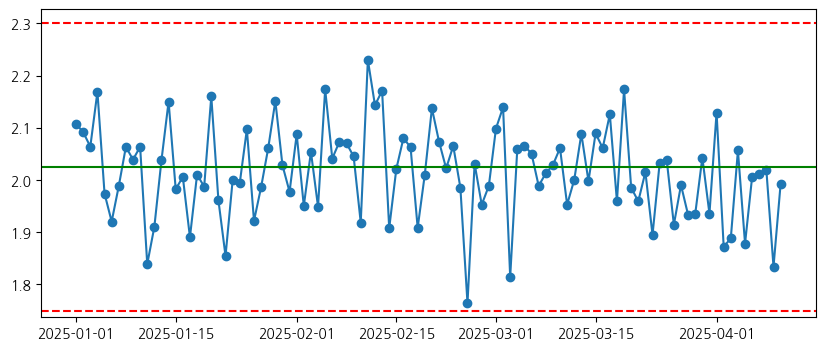

In [10]:
# 힌트: plt.axhline(값, color="red", linestyle="--")
plt.figure(figsize=(10, 4)) # 그래프의 크기 지정
plt.plot(daily, marker="o")
plt.axhline(cl, color="green")
plt.axhline(ucl, color="red", linestyle="--")
plt.axhline(lcl, color="red", linestyle="--")
plt.show() # 보여라, 그려라

## 4. 이상 판정 ✍️

**규칙 1 · 한계 이탈:** 관리한계 밖으로 나간 날을 찾습니다.

In [11]:
# 힌트: 표[(조건1) | (조건2)]
daily[ (daily > ucl) | (daily < lcl) ] # ucl 초과하거나 lcl 미만인 데이터 찾기

Series([], Freq: D, Name: vibration, dtype: float64)

**규칙 2 · 한쪽 쏠림:** 중심선 위에 8일 연속 머문 날을 찾습니다. 📋

In [13]:
(daily > cl)

timestamp
2025-01-01     True
2025-01-02     True
2025-01-03     True
2025-01-04     True
2025-01-05    False
              ...  
2025-04-06    False
2025-04-07    False
2025-04-08    False
2025-04-09    False
2025-04-10    False
Freq: D, Name: vibration, Length: 100, dtype: bool

In [14]:
(daily > cl).astype(int)

timestamp
2025-01-01    1
2025-01-02    1
2025-01-03    1
2025-01-04    1
2025-01-05    0
             ..
2025-04-06    0
2025-04-07    0
2025-04-08    0
2025-04-09    0
2025-04-10    0
Freq: D, Name: vibration, Length: 100, dtype: int32

In [15]:
above = (daily > cl).astype(int)       # 중심선 위면 1
run8 = above.rolling(8).sum() == 8     # 최근 8일이 모두 1이면 True
daily[run8]

Series([], Freq: D, Name: vibration, dtype: float64)

## 5. 드리프트 찾기 💬

**1번 셀의 `equip`만 바꾸고** 1~4번 셀을 다시 실행해 보세요. `MC-01` ~ `MC-10` 중 이상이 있는 설비를 찾습니다.

**Q1.** 드리프트가 있는 설비는 어디인가요? 언제부터, 어떤 규칙으로 잡혔나요?

> 답:


In [18]:
# 로또 번호 생성 프로그램 : 
# Miniforge Prompt --> conda activate ml_l3 --> cd C:\Users\user\ML01-main\work\student\day1
# --> steamlit run lotto.py

In [19]:
%%writefile lotto.py
import streamlit as st
import random
st.title("로또 번호 생성기")
st.markdown("### 합계가 170~200 사이인 것만 사용!")
def gen_lotto():
    while True:
        lotto = sorted( random.sample( range(1, 46), 6 ) )
        if 170 <= sum(lotto) <= 200:
            return lotto
btn = st.button("버튼을 클릭하여 로또를 생성해 주세요.")
if btn:
    for i in range(1, 6):
        lotto = gen_lotto()
        st.markdown(f"#### {i}. 행운의 번호: :green[{lotto}], {sum(lotto)}")

Overwriting lotto.py


## 6. 모니터링 앱 만들기

`%%writefile`은 셀 내용을 파일로 저장합니다. `-a`를 붙이면 파일 뒤에 이어 붙입니다.
세 셀을 차례로 실행하면 `app_spc.py`가 완성됩니다.

**① 앱 틀 📋** 데이터 읽기와 제목

In [20]:
%%writefile app_spc.py
import pandas as pd
import streamlit as st
import matplotlib.pyplot as plt
import koreanize_matplotlib

st.set_page_config(page_title="공정 모니터링", layout="wide")
st.title("공정 모니터링")


@st.cache_data      # 화면을 바꿀 때마다 파일을 다시 읽지 않게 한다
def load():
    return pd.read_parquet("../../data/factory_table.parquet")


df = load()

Overwriting app_spc.py


**② 설비 필터와 KPI 카드 ✍️**

- `st.sidebar.selectbox`: 왼쪽 사이드바의 선택 상자
- `st.columns(3)`: 화면을 3칸으로 나눔
- `칸.metric(이름, 값)`: 숫자 카드

In [21]:
%%writefile -a app_spc.py
# 힌트: st.sidebar.selectbox("이름", 목록), col.metric("이름", 값)
equip = st.sidebar.selectbox("설비 선택", sorted(df['equip_id'].unique()))
data = df[ df['equip_id'] == equip ]

col1, col2, col3 = st.columns(3)
col1.metric("생산 건수", f"{len(data)}건")
col2.metric("고장 건수", f"{data['failure'].sum()}건")
col3.metric("고장률", f"{data['failure'].mean():.1%}")

Appending to app_spc.py


**③ 추이와 관리도 📋** 위 노트북에서 한 계산을 그대로 옮겼습니다.

In [22]:
%%writefile -a app_spc.py

st.subheader("일별 고장 건수")
st.line_chart(data.resample("D", on="timestamp")["failure"].sum())

daily = data.resample("D", on="timestamp")["vibration"].mean()
base = daily.iloc[:60]
cl = base.mean()
mr_bar = base.diff().abs().mean()
ucl = cl + 2.66 * mr_bar
lcl = cl - 2.66 * mr_bar

st.subheader(f"{equip} 진동 I 관리도")
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(daily, marker="o")
ax.axhline(cl, color="green")
ax.axhline(ucl, color="red", linestyle="--")
ax.axhline(lcl, color="red", linestyle="--")
st.pyplot(fig)

st.subheader("관리한계를 벗어난 날")
out = daily[(daily > ucl) | (daily < lcl)]
st.dataframe(out.round(2))

Appending to app_spc.py


## 7. 앱 실행 (터미널)

터미널(Windows는 Miniforge Prompt)에서 **이 노트북이 있는 폴더로 이동**한 뒤 실행합니다.

```bash
conda activate ml_l3
cd work/student/day1      # 이 노트북이 있는 폴더
streamlit run app_spc.py
```

브라우저가 열리면 왼쪽에서 설비를 바꿔 가며 확인하세요. 끝낼 때는 터미널에서 `Ctrl + C`.

## 정리 💬

**Q2.** 이 앱을 현장에서 매일 쓴다면 무엇을 더 넣고 싶나요? 한 가지만 골라 보세요.

> 답:
